# Evaluating the Impact of Proxy Database Expansion on Climate Field Reconstructions Using Kolmogorov Depth

Author: Tanaya Gondhalekar

GEOL 425

December 9th 2025

## 1 Motivation


Paleoclimate reanalyses from climate field reconstruction methods are our most informative way to view past climate, yet there are few ways to assess whether two reconstructed climate fields differ significantly, especially spatially. GMST time series can show magnitude differences in cooling or warming between reconstructions, but this is not a formal or statistically meaningful measure, and standard metrics (e.g., R, CE) only provide a single number without identifying which years or regions mismatch. These differences are even harder to quantify in spatial fields, where comparisons vary both in space and time. In this project, we use three time-evolving ensemble-based 2-m air temperature fields with progressively updated proxy networks to evaluate whether enhanced networks produce meaningfully significant differences. Although expanded networks should improve coverage and reduce uncertainty, this has not been quantitatively tested, nor has the influence of proxy type and location. If reconstructions do not differ in meaningful ways, this affects proxy system modeling, climate sensitivity estimates, and model–data comparisons. To detect these differences, we apply the Kolmogorov–Depth (KD) Test (Harris et al., 2021) alongside other metrics.

In [36]:
import numpy as np
import cfr
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd

## 2 Data


For this study, we analyze three climate field reconstructions generated with the cfr package (Zhu
et al., 2024): LMRv2.1*, which emulates the LMRv2.1 framework (Tardif et al., 2019) using annu-
ally resolved proxies from the PAGES2kv2 database (Emile-Geay et al., 2017); PReSto2k, which
extends the proxy network to include CoralHydro2k (Walter et al., 2023) and Iso2k (Konecky
et al., 2020); and PReSto2k-DOCU, which further adds the DOCU-CLIM documentary dataset
(Burgdorf et al., 2023). DOCU-CLIM is notable in that it incorporates documentary evidence
rather than physical proxy archives. These records are linearly calibrated to represent near-surface
temperature. The primary datasets used in this work are the three reconstructions themselves as
well as their respective proxy database. These reconstructions are the main data that will be worked with in this notebook. 

### Load Climate Fields

In [ ]:
# LMR Reproduced
res_lmr = cfr.ReconRes('./recons/lmr_reproduce_pda_ptype_res/')
res_lmr.load(['tas', 'tas_gm'])
lmr_fd = res_lmr.recons['tas']
lmr_ts = res_lmr.recons['tas_gm']

# PReSto2k class-based
res_pc = cfr.ReconRes('./recons/lmr_reproduce_lipd/')
res_pc.load(['tas', 'tas_gm'])
pc_fd = res_pc.recons['tas']
pc_ts = res_pc.recons['tas_gm']

# PReSto2k-DOCU
res_dp = cfr.ReconRes('./recons/docu_presto/')
res_dp.load(['tas', 'tas_gm'])
dp_fd = res_dp.recons['tas']
dp_ts = res_dp.recons['tas_gm']


## 3 Methods 

To put it simply, the Kolmogorov-Depth method (KD) is a symmetric, distribution-free test that assigns a metric to a comparison between two ensemble-based climate field reconstructions. This metric shows how different two reconstructions are from each other using a significance test based on the Kolmogorov-Smirnov distribution. For a given year with two ensembles (X and Y), KD measures how "outlying" each ensemble appears from the other. First, it calculates the integrated Tukey depth of every member in both ensembles relative to X's distribution (a.k.a. how central a member is relative to the distribution), converts these to empirical CDFs ($F_X$ for X members, $G_Y$ for Y members), and computes the maximum difference. Then it repeats this process using Y as the reference distribution (symmetric). The final KD statistic is the maximum of these two directional comparisons. Hence it can detect distributional differences that might only be apparent from one reference frame and that cannot be captured by 1-D metrics like the global mean or simple variance comparisons. KD can detect spatial differences such as where some regions differ substantially while others remain similar, making it particularly useful for assessing proxy influence in climate reconstructions.

### Converted Functions from [kstat](https://github.com/trevor-harris/kstat) package (Harris et al. 2021)
All done with the use of [Claude Sonnet 4.5](https://www.anthropic.com/).

#### Integrated Tukey Depth

In [3]:
def depth_vectorized(g, fmat):
    """
    Compute univariate Tukey depth at each gridpoint.
    
    Parameters
    ----------
    g : ndarray, shape (n_gridpoints,)
        Single ensemble member to evaluate
    fmat : ndarray, shape (n_gridpoints, n_ensemble)
        Reference ensemble
    
    Returns
    -------
    ndarray, shape (n_gridpoints,)
        Depth at each gridpoint
    """
    n_ensemble = fmat.shape[1]
    
    # Broadcasting: compare g to all ensemble members
    signs = np.sign(g[:, None] - fmat)
    diff = np.abs(np.sum(signs, axis=1))
    depth_values = 1 - (diff / n_ensemble)
    
    return depth_values


def int_depth_vectorized(gmat, fmat):
    """
    Compute integrated Tukey depth for each ensemble member in gmat.
    
    Parameters
    ----------
    gmat : ndarray, shape (n_gridpoints, n_ensemble_g)
        Ensemble to evaluate
    fmat : ndarray, shape (n_gridpoints, n_ensemble_f)
        Reference ensemble
    
    Returns
    -------
    ndarray, shape (n_ensemble_g,)
        Integrated depth for each member of gmat
    """
    n_ensemble_g = gmat.shape[1]
    
    integrated_depths = np.array([
        np.mean(depth_vectorized(gmat[:, j], fmat))
        for j in range(n_ensemble_g)
    ])
    
    return integrated_depths


def reshape_for_depth(data_array, year_idx):
    """
    Extract and reshape data for a single year.
    
    Parameters
    ----------
    data_array : xarray.DataArray
        Shape (time, ens, lat, lon)
    year_idx : int
        Which year to extract
    
    Returns
    -------
    ndarray, shape (n_gridpoints, n_ensemble)
    """
    year_data = data_array[year_idx, :, :, :]
    n_ens = year_data.shape[0]
    n_gridpoints = year_data.shape[1] * year_data.shape[2]
    
    year_reshaped = year_data.values.reshape(n_ens, n_gridpoints)
    return year_reshaped.T


#### Main KStat Function
This includes the ranked CDF from Tukey Depths, and the KD-statistic calculation

In [4]:

def ks_cdf(x, n=20):
    """
    Calculate the CDF of the Kolmogorov distribution.
    
    Parameters
    ----------
    x : float
        A positive number
    n : int, optional
        Number of terms to include in the series. Default is 20.
    
    Returns
    -------
    float
        Probability P(K <= x) under Kolmogorov distribution
    
    Notes
    -----
    This implements the series expansion:
    P(K <= x) = 1 - 2 * sum_{k=1}^{n} (-1)^(k-1) * exp(-2k²x²)
    """
    if x < 0.05:
        return 0.0
    
    # Compute the alternating sum
    terms = np.array([
        ((-1)**(k-1)) * np.exp(-2 * (k**2) * (x**2))
        for k in range(1, n+1)
    ])
    
    return 1 - 2 * np.sum(terms)


def kstat(fmat, gmat):
    """
    Test if functions in fmat and gmat are equal in distribution using KD statistic.
    
    This is the core Kolmogorov Depth (KD) test statistic from Harris et al. (2021).
    
    Parameters
    ----------
    fmat : ndarray, shape (n_gridpoints, n_ensemble_f)
        First ensemble (e.g., LMR reconstruction)
    gmat : ndarray, shape (n_gridpoints, n_ensemble_g)
        Second ensemble (e.g., PReSto reconstruction)
    
    Returns
    -------
    tuple (kd_statistic, p_value)
        kd_statistic : float
            The KD test statistic
        p_value : float
            P-value under null hypothesis of equal distributions
    
    Notes
    -----
    The test is symmetric and tests H0: P = Q vs Ha: P ≠ Q
    where P and Q are the distributions of fmat and gmat.
    """
    # Step 1: Compute integrated depths
    # ff.xd: depth of fmat members relative to fmat
    ff_xd = int_depth_vectorized(fmat, fmat)
    
    # fg.xd: depth of fmat members relative to gmat  
    fg_xd = int_depth_vectorized(fmat, gmat)
    
    # gg.xd: depth of gmat members relative to gmat
    gg_xd = int_depth_vectorized(gmat, gmat)
    
    # gf.xd: depth of gmat members relative to fmat
    gf_xd = int_depth_vectorized(gmat, fmat)
    
    # Step 2: Compute empirical CDFs
    # For each depth value in ff.xd, what proportion of ff.xd values are <= it?
    ff_cdf = np.array([np.mean(ff_xd <= y) for y in ff_xd])
    
    # For each depth value in ff.xd, what proportion of gf.xd values are <= it?
    gf_cdf = np.array([np.mean(gf_xd <= y) for y in ff_xd])
    
    # For each depth value in gg.xd, what proportion of fg.xd values are <= it?
    fg_cdf = np.array([np.mean(fg_xd <= y) for y in gg_xd])
    
    # For each depth value in gg.xd, what proportion of gg.xd values are <= it?
    gg_cdf = np.array([np.mean(gg_xd <= y) for y in gg_xd])
    
    # Step 3: Compute KD statistic components
    n_f = fmat.shape[1]
    n_g = gmat.shape[1]
    rate = np.sqrt((n_g * n_f) / (n_g + n_f))
    
    # Maximum deviation using fmat as reference
    ksf = np.max(np.abs(ff_cdf - gf_cdf))
    
    # Maximum deviation using gmat as reference
    ksg = np.max(np.abs(gg_cdf - fg_cdf))
    
    # Overall KD statistic (symmetric)
    kd = max(ksf, ksg)
    
    # Step 4: Compute p-value using Kolmogorov distribution
    p_value = 1 - ks_cdf(rate * kd)
    
    return kd, p_value


def kstat_perm(fmat, gmat, perms=500, random_state=None):
    """
    Test if functions in fmat and gmat are equal in distribution using 
    permutation-based p-value.
    
    Parameters
    ----------
    fmat : ndarray, shape (n_gridpoints, n_ensemble_f)
        First ensemble
    gmat : ndarray, shape (n_gridpoints, n_ensemble_g)
        Second ensemble
    perms : int, optional
        Number of permutations for permutation test. Default is 500.
    random_state : int, optional
        Random seed for reproducibility
    
    Returns
    -------
    tuple (kd_statistic, p_value_perm)
        kd_statistic : float
            The KD test statistic
        p_value_perm : float
            Permutation-based p-value
    
    Notes
    -----
    This is more computationally expensive but doesn't rely on 
    asymptotic Kolmogorov distribution approximation.
    Useful for small samples or when asymptotic assumptions may not hold.
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    # Compute observed KD statistic
    kd_observed, _ = kstat(fmat, gmat)
    
    # Combine both ensembles
    hmat = np.column_stack([fmat, gmat])
    n_total = hmat.shape[1]
    n_f = fmat.shape[1]
    
    # Generate permutation distribution
    kd_dist = np.zeros(perms)
    
    for i in range(perms):
        # Randomly permute columns
        perm_idx = np.random.permutation(n_total)
        hstar = hmat[:, perm_idx]
        
        # Split into two groups of original sizes
        fstar = hstar[:, :n_f]
        gstar = hstar[:, n_f:]
        
        # Compute KD statistic for permuted data
        kd_dist[i], _ = kstat(fstar, gstar)
    
    # Compute permutation p-value
    p_value_perm = np.mean(kd_dist > kd_observed)
    
    return kd_observed, p_value_perm

### Full Algorithm

Also converted directly from [kstat](https://github.com/trevor-harris/kstat) package (Harris et al. 2021). 

In [5]:
def compute_kd_timeseries(data_array_1, data_array_2, use_permutation=False, perms=500):
    """
    Compute time-evolving KD statistic comparing two reconstructions.
    
    Parameters
    ----------
    data_array_1 : xarray.DataArray
        First reconstruction (e.g., LMR), shape (time, ens, lat, lon)
    data_array_2 : xarray.DataArray
        Second reconstruction (e.g., PReSto), shape (time, ens, lat, lon)
    use_permutation : bool, optional
        If True, use permutation test (slower). Default False uses asymptotic.
    perms : int, optional
        Number of permutations if use_permutation=True
    
    Returns
    -------
    dict with keys:
        'kd_stats': array (n_years,) - KD statistic per year
        'p_values': array (n_years,) - p-value per year
        'years': array (n_years,) - year labels from data
    """
    n_years = data_array_1.shape[0]
    
    kd_stats = np.zeros(n_years)
    p_values = np.zeros(n_years)
    
    for year_idx in range(n_years):
        if year_idx % 100 == 0:
            print(f"Processing year {year_idx}/{n_years} (year {data_array_1.coords['time'].values[year_idx]})...")
        
        # Prepare data for this year
        fmat = reshape_for_depth(data_array_1, year_idx)
        gmat = reshape_for_depth(data_array_2, year_idx)
        
        # Compute KD statistic
        if use_permutation:
            kd_stats[year_idx], p_values[year_idx] = kstat_perm(fmat, gmat, perms=perms)
        else:
            kd_stats[year_idx], p_values[year_idx] = kstat(fmat, gmat)
    
    return {
        'kd_stats': kd_stats,
        'p_values': p_values,
        'years': data_array_1.coords['time'].values
    }

In [6]:
from statsmodels.stats.multitest import fdrcorrection

In [ ]:
# Actual function to run, that uses the functions defined above

def compute_and_plot_kd(fd1, fd2, ts1, ts2, name1, name2, region=None):

    print(f"Computing KD statistic for {name1} vs {name2}...")
    results = compute_kd_timeseries(
        fd1, 
        fd2,
        use_permutation=False  # Use asymptotic (fast)
    )

    print(f"\nCompleted {len(results['kd_stats'])} years")
    print(f"KD range: [{results['kd_stats'].min():.4f}, {results['kd_stats'].max():.4f}]")
    print(f"P-value range: [{results['p_values'].min():.4e}, {results['p_values'].max():.4e}]")

    # Step 2: Analyze results with BY FDR correction

    
    alpha = 0.05
    pvals = results['p_values']

    # Benjamini-Yekutieli FDR correction (for arbitrary dependence)
    rejected, pvals_adjusted = fdrcorrection(
        pvals, 
        alpha=alpha, 
        method='negcorr'  # BY correction for temporal dependence
    )

    n_tests = len(pvals)
    n_significant = np.sum(rejected)

    print(f"\n=== Statistical Summary (Benjamini–Yekutieli FDR) ===")
    print(f"Significant years (FDR α={alpha}): {n_significant}/{n_tests} ({100*n_significant/n_tests:.1f}%)")
    print(f"Median KD statistic: {np.median(results['kd_stats']):.4f}")

    # Get years where p < 0.01
    sig_years_01 = results['years'][pvals < 0.01]
    print(f"Years with p < 0.01: {len(sig_years_01)} years")

    # Step 3: Compute mean difference time series

    
    # Difference: ts1.mean - ts2.mean
    mean_diff = np.abs(ts1.mean - ts2.mean)
    
    # ========================================
    # Step 3.5: Create sorted table of KD vs absolute GMST difference
    # ========================================
    
    # Sort by KD statistic (largest to smallest)
    sorted_idx = np.argsort(mean_diff)[::-1]
    
    kd_gmst_table = pd.DataFrame({
        'year': results['years'][sorted_idx],
        'kd_stat': results['kd_stats'][sorted_idx],
        'abs_gmst_diff': mean_diff[sorted_idx],
        'p_value': pvals[sorted_idx]
    })
    
    # Step 4: Two-panel visualization

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    years = results['years']

    # Find shaded regions for KD >= 0.9
    p_01_mask = results['kd_stats'] >= 0.9
    if np.any(p_01_mask):
        # Find starts and ends of contiguous regions
        diff = np.diff(np.concatenate(([False], p_01_mask, [False])).astype(int))
        starts = np.where(diff == 1)[0]
        ends = np.where(diff == -1)[0]
        
        # Add shading to top panel
        for start, end in zip(starts, ends):
            ax1.axvspan(years[start], years[end-1], color='lightblue', alpha=0.6)

    # Panel 1: KD statistic over time
    ax1.scatter(years, results['kd_stats'], alpha=0.5, s=10, c='black')

    # Add trend line
    z = np.polyfit(years, results['kd_stats'], 1)
    p = np.poly1d(z)
    ax1.plot(years, p(years), "r-", linewidth=2, label='Trend')
    ax1.set_ylabel('KD Statistic', fontsize=12)

    if region is not None:
        ax1.set_title(f'Time Evolution of KD Statistic {region}: {name1} vs {name2}', 
                     fontsize=14, fontweight='bold')
    else: 
        ax1.set_title(f'Time Evolution of KD Statistic: {name1} vs {name2}', 
                     fontsize=14, fontweight='bold')
    
    ax1.grid(True, alpha=0.3)
    ax1.axhline(y=0.27, color='#000080', linestyle='--', label='KD=0.27 (signif.)')
    ax1.legend()

    # Panel 2: Mean difference time series
    # Add shading to bottom panel (same regions)
    if np.any(p_01_mask):
        for start, end in zip(starts, ends):
            ax2.axvspan(years[start], years[end-1], color='lightblue', alpha=0.6)
    
    ax2.plot(years, mean_diff, linewidth=1, color='black')
    
    ax2.set_ylabel(r'|$\Delta$ GMST|' + f'({name1} - {name2})', fontsize=12)
    ax2.set_xlabel('Year', fontsize=12)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Store results
    results['sig_years_01'] = sig_years_01
    results['mean_diff'] = mean_diff
    results['kd_gmst_table'] = kd_gmst_table

    return results

In [8]:
# Load in xarray DataArrays from 2m surface temperature climate field

res_lmr_da = res_lmr.da['tas']
res_pc_da = res_pc.da['tas']

res_dp_da = res_dp.da['tas']

## 5 Results 

**Global**

KD and |$\Delta$ GMST| tend to rise and fall together, and because KD > 0.27 is significant, most years show meaningful differences between the reconstructions. Years with KD > 0.9 are highlighted only for visual clarity. For LMRv2.1* vs. PReSto2k, KD shows a slight increase over time and sometimes aligns with larger GMST differences, but also reflects spatial changes that the global mean does not capture. KD is even higher for LMRv2.1* vs. DOCU-PReSto, especially after about 1500 when documentary proxies appear. 
To see whether KD contains information beyond GMST, we examined selected years across high and low combinations of KD and |$\Delta$ GMST| and plotted spatial difference fields with differing proxy locations (these were made in a different notebook, just designed to pump out figures. They are present in the paper). High-KD years show strong spatial mismatches regardless of global mean behavior, while low-KD years show weak and uniform differences. These results suggest that proxy placement, rather than proxy count, is a major driver of reconstruction differences and that KD captures spatial structure that GMST alone cannot. Of course, the overall changes driven by the additional proxies are dependent on the existing networks coverage and concentration as well. 

**Regional**

To see how changes in the proxy network affect the reconstruction, we first identified where the proxy databases differ and found the largest mismatches between LMRv2.1* and PReSto2k in the tropics. Computing KD in this region shows a steeper increase than the global case, but from  plotting and obtain statistics from every subdivided region, we see that the mid-latitudes actually contain the highest percentage of significant KD years, indicating that added mid-latitude proxies have strong influence on reconstruction differences. For LMRv2.1* vs. PReSto2k-DOCU, the largest proxy additions occur in the Northern Mid-Latitudes, which also show the highest fraction of KD > 0.9 years, though this metric needs to be determined more rigorously. These results show that new proxy records do not affect all regions equally, and regional KD values mainly serve as a guide for where deeper analyses, such as EOFs or volcanic response analysis, should be focused. 


### Compute KD-Statistics for LMRv2.1* and PReSto2k-DOCU (Global)

Computing KD statistic for LMRv2.1* vs PReSto2k-DOCU...
Processing year 0/2000 (year 1)...
Processing year 100/2000 (year 101)...
Processing year 200/2000 (year 201)...
Processing year 300/2000 (year 301)...
Processing year 400/2000 (year 401)...
Processing year 500/2000 (year 501)...
Processing year 600/2000 (year 601)...
Processing year 700/2000 (year 701)...
Processing year 800/2000 (year 801)...
Processing year 900/2000 (year 901)...
Processing year 1000/2000 (year 1001)...
Processing year 1100/2000 (year 1101)...
Processing year 1200/2000 (year 1201)...
Processing year 1300/2000 (year 1301)...
Processing year 1400/2000 (year 1401)...
Processing year 1500/2000 (year 1501)...
Processing year 1600/2000 (year 1601)...
Processing year 1700/2000 (year 1701)...
Processing year 1800/2000 (year 1801)...
Processing year 1900/2000 (year 1901)...

Completed 2000 years
KD range: [0.0911, 1.0000]
P-value range: [0.0000e+00, 9.8936e-01]

=== Statistical Summary (Benjamini–Yekutieli FDR) ===
Sign

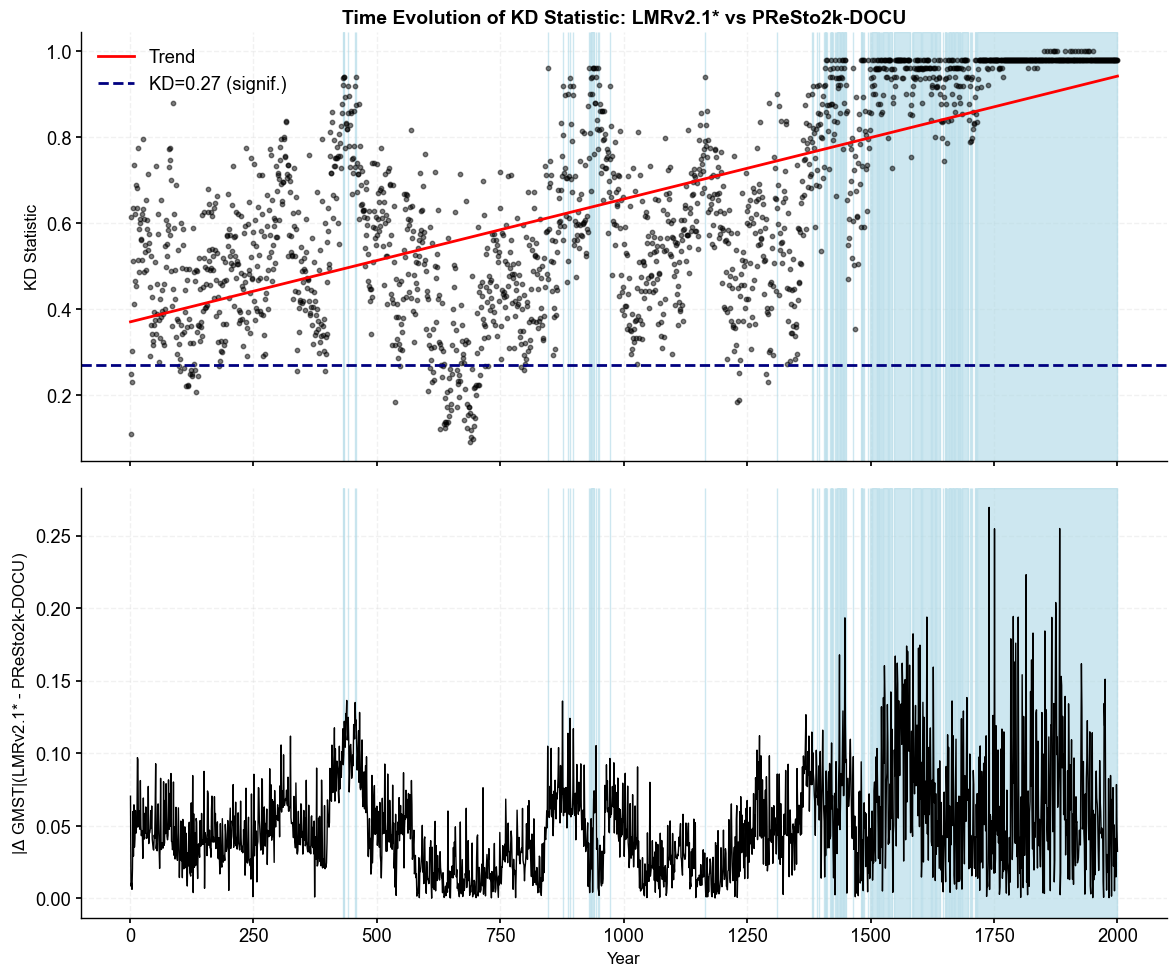

In [40]:
lmr_docu_comp = compute_and_plot_kd(res_lmr_da, res_dp_da, lmr_ts, dp_ts, 'LMRv2.1*', 'PReSto2k-DOCU')

In [10]:
# Sorted Table 

lmr_docu_comp['kd_gmst_table']


,year,kd_stat,abs_gmst_diff,p_value
0,1740,0.980000,0.269404,0.000000e+00
1,1883,0.980000,0.254854,0.000000e+00
2,1751,0.980000,0.254684,0.000000e+00
3,1815,0.980000,0.223040,0.000000e+00
4,1875,0.980000,0.203840,0.000000e+00
...,...,...,...,...
1995,586,0.560000,0.000380,7.074565e-07
1996,732,0.426667,0.000283,3.597826e-04
1997,649,0.260000,0.000235,8.134748e-02
1998,1185,0.771111,0.000158,1.171507e-12


### Compute KD-Stats for LMRv2.1* and PReSto2k

Computing KD statistic for LMRv2.1* vs PReSto2k...
Processing year 0/2000 (year 1)...
Processing year 100/2000 (year 101)...
Processing year 200/2000 (year 201)...
Processing year 300/2000 (year 301)...
Processing year 400/2000 (year 401)...
Processing year 500/2000 (year 501)...
Processing year 600/2000 (year 601)...
Processing year 700/2000 (year 701)...
Processing year 800/2000 (year 801)...
Processing year 900/2000 (year 901)...
Processing year 1000/2000 (year 1001)...
Processing year 1100/2000 (year 1101)...
Processing year 1200/2000 (year 1201)...
Processing year 1300/2000 (year 1301)...
Processing year 1400/2000 (year 1401)...
Processing year 1500/2000 (year 1501)...
Processing year 1600/2000 (year 1601)...
Processing year 1700/2000 (year 1701)...
Processing year 1800/2000 (year 1801)...
Processing year 1900/2000 (year 1901)...

Completed 2000 years
KD range: [0.0800, 0.9800]
P-value range: [0.0000e+00, 9.9719e-01]

=== Statistical Summary (Benjamini–Yekutieli FDR) ===
Significa

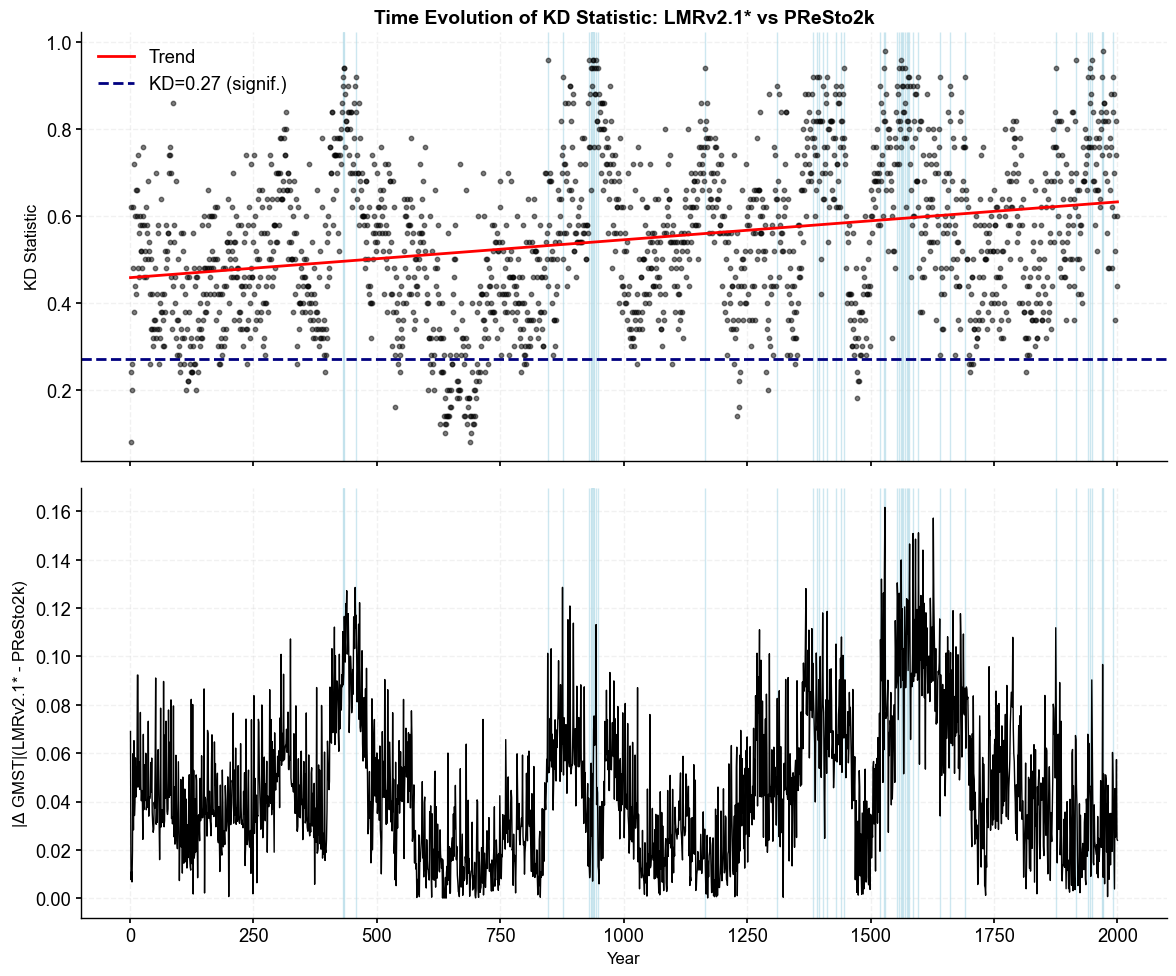

In [41]:
lmr_presto_comp = compute_and_plot_kd(res_lmr_da, res_pc_da, lmr_ts, pc_ts, 'LMRv2.1*', 'PReSto2k')

In [12]:
# Sorted Table 

lmr_presto_comp['kd_gmst_table']

,year,kd_stat,abs_gmst_diff,p_value
0,1529,0.98,0.161670,0.000000e+00
1,1627,0.80,0.157248,2.531308e-14
2,1597,0.92,0.151160,0.000000e+00
3,1586,0.90,0.150880,0.000000e+00
4,1591,0.88,0.148549,0.000000e+00
...,...,...,...,...
1995,700,0.22,0.000138,1.777182e-01
1996,1170,0.78,0.000098,1.230127e-13
1997,633,0.32,0.000078,1.195204e-02
1998,636,0.14,0.000016,7.112352e-01


### Regional Split

Instead of doing a 12 split with land/ocean masking like they did in their paper, I will do a study on 5 regions:
- High latitudes (Arctic)
- Mid Latitudes (NA, Europe, Most of Asia)
- Tropics
- Mid Latitudes (SA, Aus, Oceania, Asia)
- High Latitudes (Antarctica/Southern Ocean)

In [13]:
"""
Simple 5-region latitudinal mask
Divides globe into: High Northern, Mid Northern, Tropics, Mid Southern, High Southern
"""

import numpy as np
import xarray as xr


def make_latitudinal_mask(field):
    """
    Build a simple latitudinal region mask.
    
    Divides the globe into 5 latitudinal bands
    
    Parameters
    ----------
    field : cfr.ClimateField or xarray.DataArray
        Climate field to get the grid from
    
    Returns
    -------
    region_mask : xr.DataArray
        dims: (lat, lon), values are integer region IDs (1-5)
    """
    # Get the DataArray (handle both ClimateField and DataArray input)
    if hasattr(field, 'da'):
        da = field.da
    else:
        da = field
    
    # Get grid from first time/ensemble slice
    if 'time' in da.dims:
        if 'ens' in da.dims:
            da0 = da.isel(time=0, ens=0)
        else:
            da0 = da.isel(time=0)
    else:
        da0 = da
    
    lat = da0['lat']
    lon = da0['lon']
    
    # Start with all zeros (unassigned)
    region_mask = xr.full_like(da0, fill_value=0, dtype='int16')
    
    # Define latitudinal bands
    # Format: region_id: (name, lat_min, lat_max)
    regions = {
        1: ("High Northern Latitudes",  60,  90),
        2: ("Mid Northern Latitudes",   30,  60),
        3: ("Tropics",                 -30,  30), # this one is double in size btw
        4: ("Mid Southern Latitudes",  -60, -30),
        5: ("High Southern Latitudes", -90, -60),
    }
    
    # Apply each region (simple latitude bands)
    for rid, (name, lat_min, lat_max) in regions.items():
        lat_mask = (lat >= lat_min) & (lat <= lat_max)
        # Broadcast to full grid
        mask = lat_mask
        region_mask = region_mask.where(~mask, rid)
    
    region_mask.name = "region_id"
    region_mask.attrs["regions"] = {rid: info[0] for rid, info in regions.items()}
    
    return region_mask

In [14]:
# mask should be the same for all recons, so we just use one 

region_mask = make_latitudinal_mask(res_lmr.recons['tas'])

Text(0.5, 1.0, 'Latitudinal Regions')

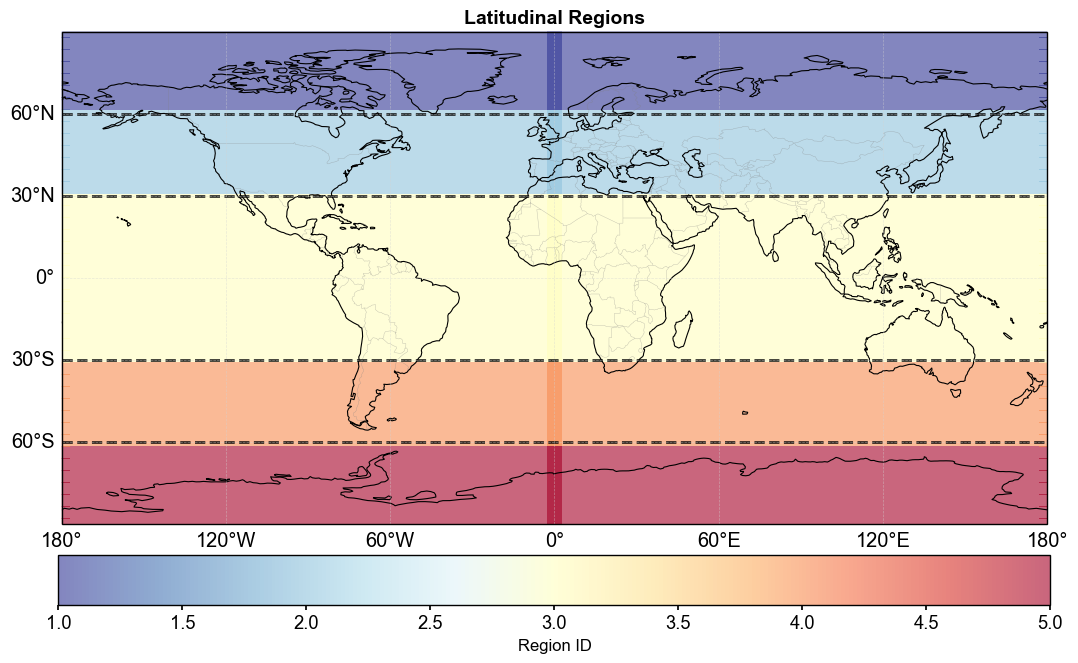

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(16, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot the latitudinal bands
im = ax.pcolormesh(
    region_mask.lon, 
    region_mask.lat, 
    region_mask.values,
    transform=ccrs.PlateCarree(),
    cmap='RdYlBu_r',
    alpha=0.6
)

# Add continent outlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black')
ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor='gray', alpha=0.5)

# Add horizontal lines at boundaries
ax.axhline(60, color='black', linewidth=2, linestyle='--', alpha=0.8)
ax.axhline(30, color='black', linewidth=2, linestyle='--', alpha=0.8)
ax.axhline(-30, color='black', linewidth=2, linestyle='--', alpha=0.8)
ax.axhline(-60, color='black', linewidth=2, linestyle='--', alpha=0.8)

# Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

# Colorbar
cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('Region ID', fontsize=12)

ax.set_title('Latitudinal Regions', fontsize=14, fontweight='bold')


In [ ]:
# Same function as above just with additional regional parameters

def compute_and_plot_kd_reg(fd1, fd2, ts1, ts2, name1, name2, region=None):

    print(f"Computing KD statistic for {name1} vs {name2}...")
    results = compute_kd_timeseries(
        fd1, 
        fd2,
        use_permutation=False  # Use asymptotic (fast)
    )

    print(f"\nCompleted {len(results['kd_stats'])} years")
    print(f"KD range: [{results['kd_stats'].min():.4f}, {results['kd_stats'].max():.4f}]")
    print(f"P-value range: [{results['p_values'].min():.4e}, {results['p_values'].max():.4e}]")

    # Step 2: Analyze results with BY FDR correction
    
    alpha = 0.05
    pvals = results['p_values']

    # Benjamini-Yekutieli FDR correction (for arbitrary dependence)
    rejected, pvals_adjusted = fdrcorrection(
        pvals, 
        alpha=alpha, 
        method='negcorr'  # BY correction for temporal dependence
    )

    n_tests = len(pvals)
    n_significant = np.sum(rejected)

    print(f"\n=== Statistical Summary (Benjamini–Yekutieli FDR) ===")
    print(f"Significant years (FDR α={alpha}): {n_significant}/{n_tests} ({100*n_significant/n_tests:.1f}%)")
    print(f"Median KD statistic: {np.median(results['kd_stats']):.4f}")

    # Get years where p < 0.01
    sig_years_01 = results['years'][pvals < 0.01]
    print(f"Years with p < 0.01: {len(sig_years_01)} years ({(len(sig_years_01)/2000) * 100}%)")
    
    # Count years where KD >= 0.9
    high_kd_mask = results['kd_stats'] >= 0.9
    n_high_kd = np.sum(high_kd_mask)
    total_years = len(results['kd_stats'])
    print(f"Years with KD >= 0.9: {n_high_kd}/{total_years} ({100*n_high_kd/total_years:.1f}%)")
    

    # Step 3: Compute mean difference time series
    
    # Difference: ts1.mean - ts2.mean
    mean_diff = np.abs(ts1.mean(dim='ens').values - ts2.mean(dim='ens').values)
    
    # Step 3.5: Create sorted table of KD vs absolute GMST difference
    
    # Sort by KD statistic (largest to smallest)
    sorted_idx = np.argsort(mean_diff)[::-1]
    
    kd_gmst_table = pd.DataFrame({
        'year': results['years'][sorted_idx],
        'kd_stat': results['kd_stats'][sorted_idx],
        'abs_gmst_diff': mean_diff[sorted_idx],
        'p_value': pvals[sorted_idx]
    })
    

    # Step 4: Two-panel visualization

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    years = results['years']

    # Find shaded regions for KD >= 0.9
    p_01_mask = results['kd_stats'] >= 0.9
    if np.any(p_01_mask):
        # Find starts and ends of contiguous regions
        diff = np.diff(np.concatenate(([False], p_01_mask, [False])).astype(int))
        starts = np.where(diff == 1)[0]
        ends = np.where(diff == -1)[0]
        
        # Add shading to top panel
        for start, end in zip(starts, ends):
            ax1.axvspan(years[start], years[end-1], color='lightblue', alpha=0.6)

    # Panel 1: KD statistic over time
    ax1.scatter(years, results['kd_stats'], alpha=0.5, s=10, c='black')

    # Add trend line
    z = np.polyfit(years, results['kd_stats'], 1)
    p = np.poly1d(z)
    ax1.plot(years, p(years), "r-", linewidth=2, label='Trend')
    ax1.set_ylabel('KD Statistic', fontsize=12)

    if region is not None:
        ax1.set_title(f'Time Evolution of KD Statistic {region}: {name1} vs {name2}', 
                     fontsize=14, fontweight='bold')
    else: 
        ax1.set_title(f'Time Evolution of KD Statistic: {name1} vs {name2}', 
                     fontsize=14, fontweight='bold')
    
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Panel 2: Mean difference time series
    # Add shading to bottom panel (same regions)
    if np.any(p_01_mask):
        for start, end in zip(starts, ends):
            ax2.axvspan(years[start], years[end-1], color='lightblue', alpha=0.6)
    
    ax2.plot(years, mean_diff, linewidth=1, color='black')
    
    ax2.set_ylabel(r'|$\Delta$ MST|' + f'({name1} - {name2})', fontsize=12), 
    ax2.set_xlabel('Year', fontsize=12)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Store results
    results['sig_years_01'] = sig_years_01
    results['mean_diff'] = mean_diff
    results['kd_gmst_table'] = kd_gmst_table

    return results

In [17]:
# Northern High Latitudes
reg1_lmr = res_lmr.da['tas'].sel(lat=slice(60, 90))
reg1_pc = res_pc.da['tas'].sel(lat=slice(60, 90))
reg1_dp = res_dp.da['tas'].sel(lat=slice(60, 90))

# Northern Mid Latitudes
reg2_lmr = res_lmr.da['tas'].sel(lat=slice(30, 60))
reg2_pc = res_pc.da['tas'].sel(lat=slice(30, 60))
reg2_dp = res_dp.da['tas'].sel(lat=slice(30, 60))

# Tropics
reg3_lmr = res_lmr.da['tas'].sel(lat=slice(-30, 30))
reg3_pc = res_pc.da['tas'].sel(lat=slice(-30, 30))
reg3_dp = res_dp.da['tas'].sel(lat=slice(-30, 30))

# Southern Mid Latitudes
reg4_lmr = res_lmr.da['tas'].sel(lat=slice(-60,-30))
reg4_pc = res_pc.da['tas'].sel(lat=slice(-60, -30))
reg4_dp = res_dp.da['tas'].sel(lat=slice(-60, -30))

# Southern High Latitudes
reg5_lmr = res_lmr.da['tas'].sel(lat=slice(-90,-60))
reg5_pc = res_pc.da['tas'].sel(lat=slice(-90, -60))
reg5_dp = res_dp.da['tas'].sel(lat=slice(-90, -60))

In [18]:
import numpy as np

def weighted_mean_ts(da):
    """
    Calculate area-weighted spatial mean for ensemble data.
    Returns (time, ens) for KD analysis.
    
    Parameters:
    -----------
    da : xarray.DataArray
        DataArray with (time, ens, lat, lon) dimensions
    
    Returns:
    --------
    xarray.DataArray : Shape (time, ens) - suitable for KD analysis
    """
    # Calculate weights based on cosine of latitude
    weights = np.cos(np.deg2rad(da.lat))
    weights.name = "weights"
    
    # Weight the data and take mean over spatial dimensions only
    da_weighted = da.weighted(weights)
    
    # Mean over lat and lon, keeping time and ens
    # Result will be (time, ens)
    return da_weighted.mean(dim=['lat', 'lon'])


In [19]:

# Extract regional time series with ensemble dimension weighting 

# Northern High Latitudes
reg1_lmr_ts = weighted_mean_ts(res_lmr.da['tas'].sel(lat=slice(60, 90)))
reg1_pc_ts = weighted_mean_ts(res_pc.da['tas'].sel(lat=slice(60, 90)))
reg1_dp_ts = weighted_mean_ts(res_dp.da['tas'].sel(lat=slice(60, 90)))

#northern mid
reg2_lmr_ts = weighted_mean_ts(res_lmr.da['tas'].sel(lat=slice(30, 60)))
reg2_pc_ts = weighted_mean_ts(res_pc.da['tas'].sel(lat=slice(30, 60)))
reg2_dp_ts = weighted_mean_ts(res_dp.da['tas'].sel(lat=slice(30, 60)))

#tropics
reg3_lmr_ts = weighted_mean_ts(res_lmr.da['tas'].sel(lat=slice(-30, 30)))
reg3_pc_ts = weighted_mean_ts(res_pc.da['tas'].sel(lat=slice(-30, 30)))
reg3_dp_ts = weighted_mean_ts(res_dp.da['tas'].sel(lat=slice(-30, 30)))

#southern mid
reg4_lmr_ts = weighted_mean_ts(res_lmr.da['tas'].sel(lat=slice(-60,-30)))
reg4_pc_ts = weighted_mean_ts(res_pc.da['tas'].sel(lat=slice(-60,-30)))
reg4_dp_ts = weighted_mean_ts(res_dp.da['tas'].sel(lat=slice(-60,-30)))

#southern high
reg5_lmr_ts = weighted_mean_ts(res_lmr.da['tas'].sel(lat=slice(-90, -60)))
reg5_pc_ts = weighted_mean_ts(res_pc.da['tas'].sel(lat=slice(-90, -60)))
reg5_dp_ts = weighted_mean_ts(res_dp.da['tas'].sel(lat=slice(-90, -60)))


### Paper Regional Analysis Figures

For the sake of storage and relevance, I will only visualize the KD vs mean surface temperature for the Tropics and Northern Mid Latitudes for our two respective reconstruction comparisons. The rest of the statistics will be stored inthe respective compute and plot objects. Running the entirety is how I obtained values for Table 4 and 5 of my paper. 

In [ ]:
reg1 = compute_and_plot_kd_reg(reg1_lmr, reg1_dp, reg1_lmr_ts, reg1_dp_ts,"LMRv2.1*", "PReSto2k-DOCU", region='Northern High Latitudes' )

Computing KD statistic for LMRv2.1* vs PReSto2k-DOCU...
Processing year 0/2000 (year 1)...
Processing year 100/2000 (year 101)...
Processing year 200/2000 (year 201)...
Processing year 300/2000 (year 301)...
Processing year 400/2000 (year 401)...
Processing year 500/2000 (year 501)...
Processing year 600/2000 (year 601)...
Processing year 700/2000 (year 701)...
Processing year 800/2000 (year 801)...
Processing year 900/2000 (year 901)...
Processing year 1000/2000 (year 1001)...
Processing year 1100/2000 (year 1101)...
Processing year 1200/2000 (year 1201)...
Processing year 1300/2000 (year 1301)...
Processing year 1400/2000 (year 1401)...
Processing year 1500/2000 (year 1501)...
Processing year 1600/2000 (year 1601)...
Processing year 1700/2000 (year 1701)...
Processing year 1800/2000 (year 1801)...
Processing year 1900/2000 (year 1901)...

Completed 2000 years
KD range: [0.0778, 0.9800]
P-value range: [0.0000e+00, 9.9879e-01]

=== Statistical Summary (Benjamini–Yekutieli FDR) ===
Sign

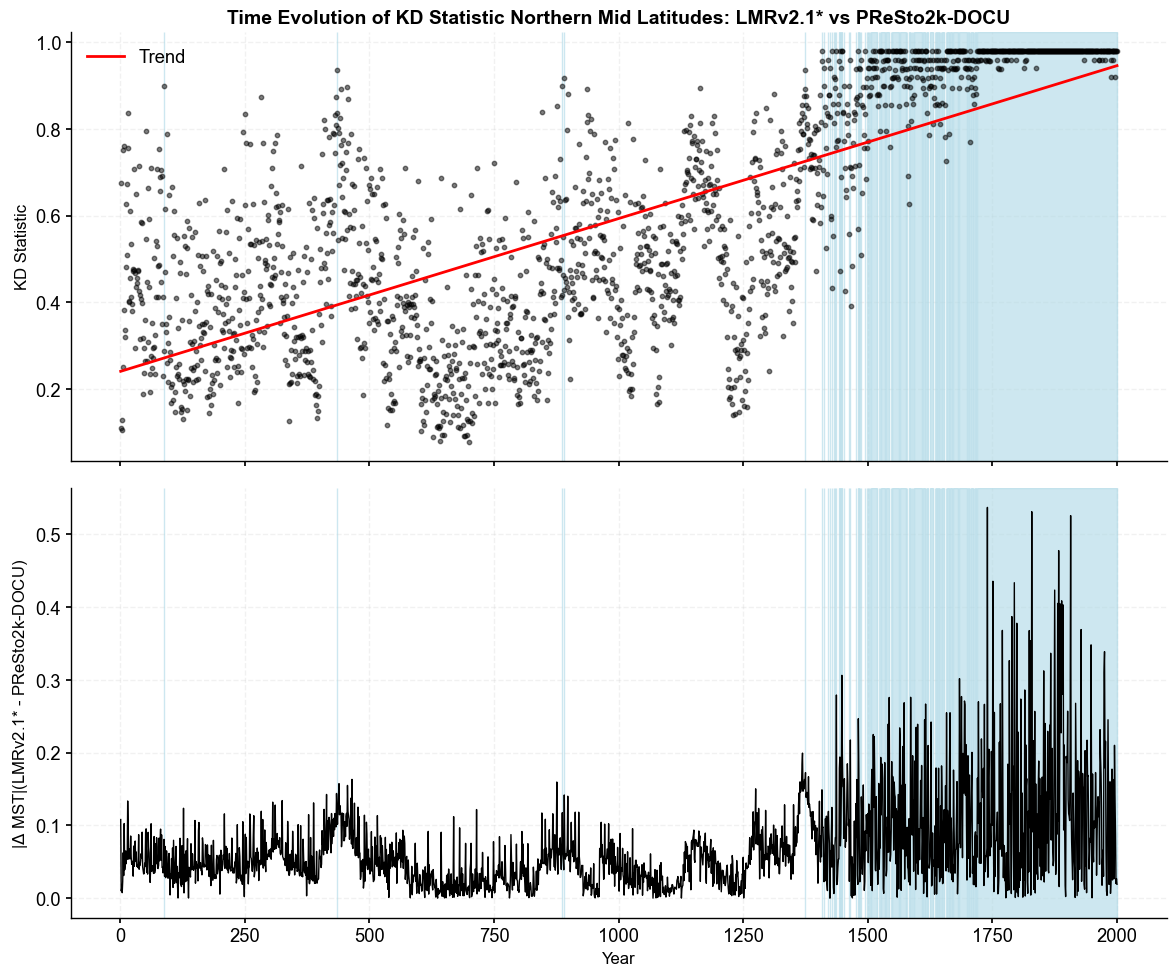

In [43]:
reg2 = compute_and_plot_kd_reg(reg2_lmr, reg2_dp, reg2_lmr_ts, reg2_dp_ts,"LMRv2.1*", "PReSto2k-DOCU", region='Northern Mid Latitudes' )

In [ ]:
reg3 = compute_and_plot_kd_reg(reg3_lmr, reg3_dp, reg3_lmr_ts, reg3_dp_ts,"LMRv2.1*", "PReSto2k-DOCU", region='Tropics' )

In [ ]:
reg4 = compute_and_plot_kd_reg(reg4_lmr, reg4_dp, reg4_lmr_ts, reg4_dp_ts,"LMRv2.1*", "PReSto2k-DOCU", region='Southern Mid Latitudes' )

In [ ]:
reg5 = compute_and_plot_kd_reg(reg5_lmr, reg5_dp, reg5_lmr_ts, reg5_dp_ts,"LMRv2.1*", "PReSto2k-DOCU", region='Southern High Latitudes' )

In [ ]:
reg11 = compute_and_plot_kd_reg(reg1_lmr, reg1_pc, reg1_lmr_ts, reg1_pc_ts,"LMRv2.1*", "PReSto2k", region='Northern High Latitudes' )

In [ ]:
reg22 = compute_and_plot_kd_reg(reg2_lmr, reg2_pc, reg2_lmr_ts, reg2_pc_ts,"LMRv2.1*", "PReSto2k", region='Northern Mid Latitudes' )

Computing KD statistic for LMRv2.1* vs PReSto2k...
Processing year 0/2000 (year 1)...
Processing year 100/2000 (year 101)...
Processing year 200/2000 (year 201)...
Processing year 300/2000 (year 301)...
Processing year 400/2000 (year 401)...
Processing year 500/2000 (year 501)...
Processing year 600/2000 (year 601)...
Processing year 700/2000 (year 701)...
Processing year 800/2000 (year 801)...
Processing year 900/2000 (year 901)...
Processing year 1000/2000 (year 1001)...
Processing year 1100/2000 (year 1101)...
Processing year 1200/2000 (year 1201)...
Processing year 1300/2000 (year 1301)...
Processing year 1400/2000 (year 1401)...
Processing year 1500/2000 (year 1501)...
Processing year 1600/2000 (year 1601)...
Processing year 1700/2000 (year 1701)...
Processing year 1800/2000 (year 1801)...
Processing year 1900/2000 (year 1901)...

Completed 2000 years
KD range: [0.0600, 0.9800]
P-value range: [0.0000e+00, 9.9999e-01]

=== Statistical Summary (Benjamini–Yekutieli FDR) ===
Significa

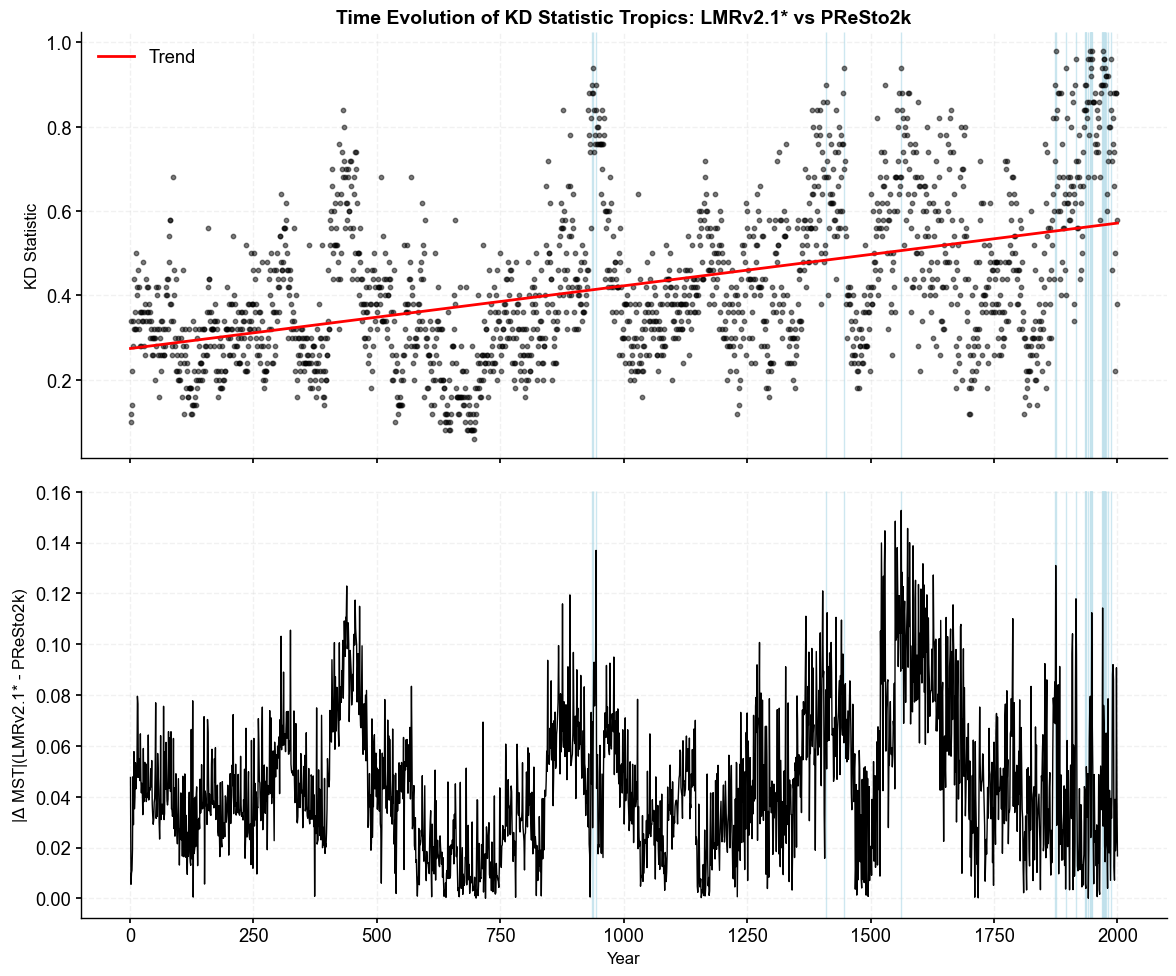

In [44]:
reg33 = compute_and_plot_kd_reg(reg3_lmr, reg3_pc, reg3_lmr_ts, reg3_pc_ts,"LMRv2.1*", "PReSto2k", region='Tropics' )

In [ ]:
reg44 = compute_and_plot_kd_reg(reg4_lmr, reg4_pc, reg4_lmr_ts, reg4_pc_ts,"LMRv2.1*", "PReSto2k", region='Southern Mid Latitudes' )

In [ ]:
reg55 = compute_and_plot_kd_reg(reg5_lmr, reg5_pc, reg5_lmr_ts, reg5_pc_ts,"LMRv2.1*", "PReSto2k", region='Southern High Latitudes' )

## 6 Discussion/Conclusion

KD increases through time globally as the proxy networks expand, but regional patterns show that proxy placement, not just proxy count, drives where reconstructions diverge. KD also identifies years where spatial differences are large even when |$\Delta$ GMST| is small, confirming that global mean metrics alone cannot capture spatial mismatches. Regions with unique proxy types or new additions show the strongest divergence, consistent with the regional KD results. Overall, KD shows that proxy placement and proxy-system behavior play a major role in shaping the reconstruction, so these factors need to be studied more in depth when interpreting and/or designing new paleocli-
mate data assimilation frameworks. KD works best in conjunction with other metrics, helping pinpoint the years and regions that deserve further scientific investigation. 